# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wntr
import wntr.graphics as wntr_graphics
import networkx as nx
import os
import torch
import random
from torch_geometric.data import Data
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

from data_use import (
    normalizar_residuo, taxa_exceedance, calcular_residuo
)

from data_access import (
    get_all, leak_info
)

from data_menagement import (
    process_scenario_data
)

c:\Users\Mirella Fontinelle\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Prep G

In [2]:
def map_graph(scenarios):
    # carregar topologia
    wn = wntr.network.WaterNetworkModel(scenarios[118]['inp'])
    G = wn.to_graph().to_undirected()

    # lista em ordem fixa de nós
    list_nodes = sorted(wn.junction_name_list, key=int)
    nodes_index = {node: i for i, node in enumerate(list_nodes)} # enumerate devolve par (posição, valor) pra cada elemento de uma lista

    print(list_nodes)
    print(nodes_index)

    return G, list_nodes, nodes_index

In [ ]:
def build_edge(G, nodes_index):
    # construir edge_index bidirecional
    start_edge = []
    end_edge = []

    for u, v in G.edges(): 
        # pula qualquer aresta que envolva um nó fora do mapeamento (reservatório)
        if u not in nodes_index or v not in nodes_index:
            continue
        
        idx_u = nodes_index[u]
        idx_v = nodes_index[v]

        start_edge.extend([idx_u, idx_v]) # .extend adiciona múltiplos elementos ao final de uma lista de uma só vez
        end_edge.extend([idx_v, idx_u])

    # cria tensor no formato certo
    edge_index = torch.tensor([start_edge, end_edge], dtype=torch.long)

    return edge_index


In [ ]:
def build_scenario_data_graph(item, list_nodes, nodes_index, edge_index, janela_dias, window_size, step):
    list_data = []

    for n, item in item.items():
        dfs_nodes, leak_intervals, total_steps = process_scenario_data(item, list_nodes, janela_dias)

        # cada pedaço dão 24 horas de histórico
        for t_init in range(0, total_steps - window_size + 1, step):
            t_end = t_init + window_size

            # dentro de cada janela de 24 horas, cria-se um grafo novo (Data) para a GNN
            # cria a matriz de features x (len com todos nodes da rede) e correspondência y
            n_nodes = len(list_nodes)
            x = torch.zeros((n_nodes, 1), dtype=torch.float)
            y = torch.zeros(n_nodes, dtype=torch.long)

            # for each node, pega a tb tratada (dfs_nodes), cuts 24h from current window e calc mean error_normalizado
            # mean.error_normalizado = feature x[node] naquele grafo
            for node in list_nodes:
                idx = nodes_index[node]
                df_node = dfs_nodes[node]

                # extract slice from error_normalizado nessa window
                slice = df_node.loc[t_init:t_end, 'error_normalizado']

                # window resume: mean(val) do error_normalizado nesse período 
                # pode ser .max() também
                val_feature = slice.mean()
                x[idx, 0] = float(val_feature)

                # gabarito
                is_leaking = False
                for leak_node, (start, end) in  leak_intervals.items():
                    # leakege is happening in this window and in this node?
                    if str(node) == str(leak_node) and not (t_end < start or t_init > end):
                        is_leaking = True
                        break

                y[idx] = 1 if is_leaking else 0

        data = Data(x=x, edge_index=edge_index, y=y)
        list_data.append(data)

    return list_data

## Refactor: Transição de "Momento de Pico" para "Sliding Windows"

### 1. Por quê?

Anteriormente, a primeira feature do modelo era focada em **momentos de pico**, sendo a avalição de instantes isolados em que o resíduo ultrapassava um limiar crítico. A modelagem utilizando Redes Neurais em Grafos (GNNs) esbarrou em limitações físicas e matemáticas.

- **Suscetibilidade a Ruído (Falsos Positivos):** Avaliar um único *timestep* torna o modelo vulnerável a anomalias instantâneas e benignas da rede (como o acionamento de uma bomba, um fechamento abrupto de válvula ou oscilações de sensor), que geram picos isolados, mas não são vazamentos reais.
- **Perda do Contexto Temporal:** Um vazamento físico de água não é um evento de um milissegundo; ele possui persistência e altera o padrão de despressurização ao longo do tempo. 

**Instrução do orientador:** Técnica de **Sliding Windows**.
Ao invés de usar picos isolados, o modelo passa a analisar o comportamento sustentado da rede em blocos contínuos de tempo (ex: janelas de 24 horas). Isso permite que a GNN aprenda a "assinatura temporal" de um vazamento prolongado.


### 2. Implementação Técnica e Refatoração

Para viabilizar a técnica de Sliding Windows, a arquitetura de extração de dados passou por um grande refactor, principalmente na função `build_scenario_data`:

* Os 17.500 *timesteps* contínuos de um cenário não são mais convertido em um único grafo gigante. A função agora recorta esse histórico e gera múltiplos grafos sequenciais, onde cada grafo representa a rede em uma janela específica (de `t_inicio` a `t_fim`).

* Em vez de alimentar a rede com o erro de um único ponto no tempo, a feature de entrada passou a ser uma agregação estatística. O `error_normalizado` de todos os instantes dentro da janela de 24 horas é extraído para calcular a média daquele período (pensar melhor). 

* O tensor `data.x` resultante **não representa o histórico de um único nó**. Ele é uma matriz que contém o valor médio daquela janela temporal para **todos os nós** da rede simultaneamente.
  > Ou seja, significa que, com base na média de todos os `error_normalizado` de um dia inteiro para um nó, ele poderá ter seu desvio padrão resumido em 24h.

* **Preservação da Escala Global (`x_stack`):** 
  Como a rede neural avalia as "fotografias" (`data.x`) isoladamente, a normalização espacial não poderia ser feita janela a janela (o que destruiria o contexto de grandeza entre elas). O `StandardScaler` foi treinado sobre a variável `x_stack`, que empilha todas as janelas, de todos os nós, de todos os cenários. Isso garante que a média `0.0` seja ancorada no comportamento histórico global do dataset, permitindo que a GNN diferencie uma janela normal de uma janela anômala através da variância.


### 3. Por que não janela semanal?

O consumo de água em uma cidade segue o padrão dia-noite (24h).
Uma janela de 1 semana iria diluir o sinal do vazamento, isso suavizaria a queda de pressão provocada pelo vazamento e sumiria no ruído estatístico da semana inteira.

Com cenários que tem 17.500 timesteps, usar janelas de 48 steps com `step=48` vai gerar uma quantidade de grafos de treino sem deixar o modelo fixado em detalhes logos e nem perdido detalhes curtos.

Processa um cenário por vez, fazendo slicing a cada 24h e retorna uma lista de grafos referentes àquele cenário. Cada grafo tem armazenado um valor específico em cada nó.

### 4. Baseline segura

Cenários com múltiplos vazamentos precisam do início do primeiro vazamento como referência, pois é antes de qualquer alteração crítica, mantendo a média saudável.

O `earliest_start` na função `build_scenario_data` passa por todos os vazamentos do cenário, identifica o menor `start` absoluto e usa isso para calcular o baseline de normalização em um momento em que a rede está livre.


# Action

In [ ]:
scenarios = get_all("train")
    # path
    # inp
    # info
    # leaks
    # pressures

G, list_nodes, nodes_index = map_graph(scenarios)
edge_index = build_edge(G, nodes_index)

data_list_train = build_scenario_data_graph(scenarios, G, list_nodes, nodes_index, edge_index, janela_dias=14, window_size=48, step=48)


['2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32']
{'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, '11': 9, '12': 10, '13': 11, '14': 12, '15': 13, '16': 14, '17': 15, '18': 16, '19': 17, '20': 18, '21': 19, '22': 20, '23': 21, '24': 22, '25': 23, '26': 24, '27': 25, '28': 26, '29': 27, '30': 28, '31': 29, '32': 30}


In [ ]:
# normalização

from sklearn.preprocessing import StandardScaler

# coleta todos os tensores list_train para feed the Scaler
all_val = []
for data in data_list_train:
    all_val.append(data.x.numpy()) # pega a matriz (32, 1) de cada grafo

x_stack = np.vstack(all_val) # empilha tudo em uma única coluna de sll node from all scnenarios

# train Scaler (aprende a média e  desvio padrão)
scaler = StandardScaler()
scaler.fit(x_stack)

# aplica nova escala em cada objeto Data da lista
for data in data_list_train:
    x_transformed = scaler.transform(data.x.numpy())
    data.x = torch.tensor(x_transformed, dtype=torch.float)


## Normalizações
### Normalização física por nó (Z-Score de baseline)

O objetivo era padronizar o resíduo de pressão de cada nó em relação ao seu próprio histórico (pré-vazamento).

Para cada nó, foi calculado o resíduo móvel de pressão. 
$$\text{error\_movel} = \text{Value} - \text{esperado\_movel}$$
  2. Isola-se a série temporal referente ao período pré-vazamento ($t < \text{start}$) para extrair a média ($\mu_{\text{baseline}}$) e o desvio-padrão ($\sigma_{\text{baseline}}$) históricos daquele nó.
  3. Aplica-se a padronização Z-score sobre a série inteira:
     $$z = \frac{\text{error\_movel} - \mu_{\text{baseline}}}{\sigma_{\text{baseline}}}$$

**Por quê?** 

Cada ponto da rede possui características físicas distintas (elevação, proximidade com reservatórios, diâmetro dos tubos). Isso garante que a referência normal de todos os nós seja centralizada em $0$ durante a operação saudável, medindo as oscilações de pressão em unidades de desvio-padrão em relação ao próprio comportamento do nó.

### Padronização global do dataset (StandardScaler)

O objetivo era reescalar a distribuição global de atributos dos grafos para garantir estabilidade e eficiência no treinamento da GNN.

A partir de lista de objetos `Data` do PyTorch Geometric (`data_list_train`), todos os tensores de features $x$ de todos os nós e cenários de treino.

O `StandardScaler` do `scikit-learn` se ajusta sobre esse vetor consolidado para aprender a média e o desvio-padrão globais dos dados. A matriz $x$ de cada grafo é transformada, reconvertendo os valores para tensores do PyTorch (`torch.float`)

**Por quê?** 

Ajusta a amplitude geral da feature de entrada do dataset, comprimindo a escala.


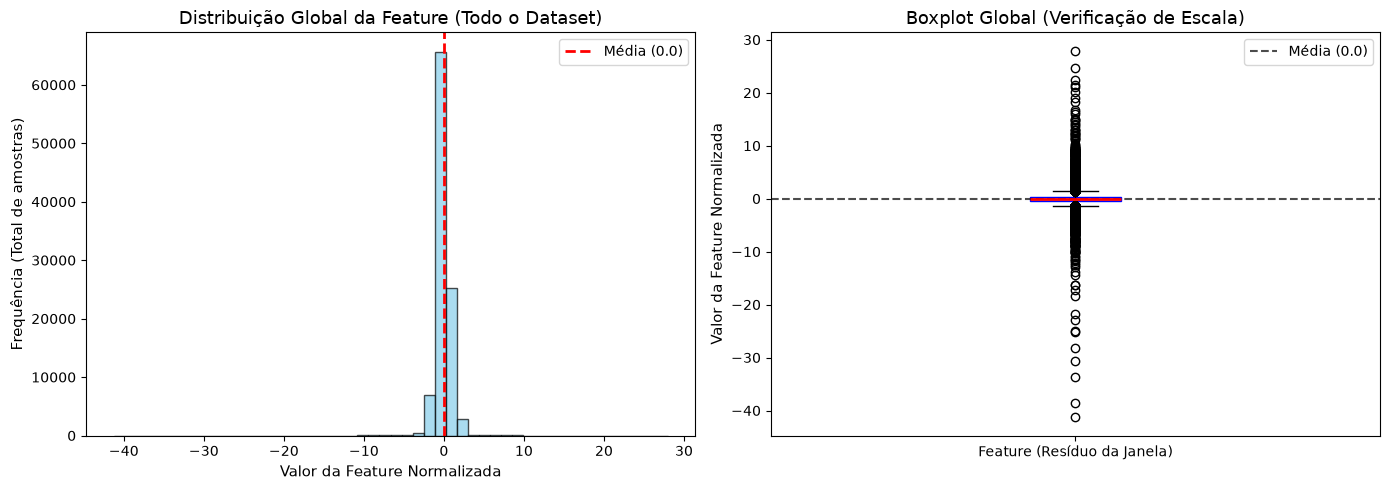

In [ ]:
# 1. Transformar O DATASET INTEIRO de uma vez
# Isso pega a sua pilha completa (todas as janelas de tempo de todos os nós)
x_stack_transformed = scaler.transform(x_stack)

# 2. Criar a figura com dois gráficos lado a lado
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# --- GRÁFICO 1: Histograma Global ---
ax[0].hist(x_stack_transformed, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
ax[0].axvline(0, color='red', linestyle='--', linewidth=2, label='Média (0.0)')
ax[0].set_title('Distribuição Global da Feature (Todo o Dataset)', fontsize=13)
ax[0].set_xlabel('Valor da Feature Normalizada', fontsize=11)
ax[0].set_ylabel('Frequência (Total de amostras)', fontsize=11)
ax[0].legend()

# --- GRÁFICO 2: Boxplot Global ---
ax[1].boxplot(x_stack_transformed, patch_artist=True, 
              boxprops=dict(facecolor="skyblue", color="blue"),
              medianprops=dict(color="red", linewidth=2))
# Linha guia no zero
ax[1].axhline(0, color='black', linestyle='--', alpha=0.7, label='Média (0.0)')
ax[1].set_title('Boxplot Global (Verificação de Escala)', fontsize=13)
ax[1].set_ylabel('Valor da Feature Normalizada', fontsize=11)
ax[1].set_xticklabels(['Feature (Resíduo da Janela)'])
ax[1].legend()

plt.tight_layout()
plt.show()

## Validação com plotagem
**Objetivo**: Validar a aplicação da dupla normalização (temporal-local via média móvel e espacial-global via `StandardScaler`) sobre o dataset completo de treinamento.

---

### 1. Construção dos dados
**Cálculo do `error_movel`(resíduo bruto)**

Definição do comportamento esperado para cada nó. Agrupa-se cada instante do dia em grupos de 14 dias e calcula-se a média da pressão de cada horário. O `error_movel` é a diferença entre a pressão do momento em análise e a média do mesmo horário nos últimos 14 dias para o mesmo nó. 

Os primeiros dias (antes de 14 dias terem se passado) são registrados com `error_movel` = 0.

**Normalização local / Z-Score** 

O `error_movel`, então, é convertido para unidades de desvio-padrão (Z-Score) e o **Baseline** é definido como a média e o desvio-padrão do período saudável do cenário (antes do primeiro vazamento).

Assim, o `error_normalizado` mede a situação do nó em relação ao seu período saudável.

**Window Slicing method** 

Recorte desse histórico em janelas de 24 horas. O resumo do comportamento daquele nó naquele dia inteiro é feito pela medição da média do `error_normalizado`. 

Esse valor passa a ser a feature bruta inicial (x) daquele nó específico, naquele grafo.

**Normalização global**
Por fim, as features temporais de todos os nós, de todos os cenários, são empilhadas em uma matriz global `x_stack`, para que o `StandardScaler` aplique o último **Z-Score**, definindo a média de toda a rede como zero.

Isso foi feito para garantir a estabilidade matemática do Gradient Descent durante o treino, mas preservando a diferença física de comportamento entre nós de alta e baixa pressão.

---

### 2. Interpretação do estado dos dados

Os gráficos (Histograma e Boxplot) representam a distribuição global do `x_stack_transformed`, criado para unificar todo o histórico da rede em um único tensor contínuo de features, contendo todas as janelas de tempo de todos os nós e cenários.

> Não foi possível utilizar `data.x` diretamente porque na arquitetura de Grafos (GNN) ele representa um fragmento de 24 horas, e o loop `for i, data enumetare(data_list_train)` não foi utilizado, pois o Matplotlib geraria milhares de gráficos isolados.

**Distribuição geral do Histograma**

Apresenta uma distribuição altamente concentrada no centro, com uma barra grande exatamente sobre a linha vermelha da média (`0.0`). Isso comprova que o `StandardScaler` ancorou a média de todo o histórico no eixo zero. 

Como se trata de uma rede de distribuição de água, a esmagadora maioria das janelas temporais reflete o estado normal de operação da rede (sem vazamentos), onde a pressão real é quase idêntica à média móvel esperada (resíduo próximo a zero).

**Verificação de anomalias**

O Intervalo Interquartil (IQR) está colado no eixo zero. Isso confirma que a variância do estado "saudável" da rede é muito pequena e padronizada. 

Os pontos que se estendem até -40 e +30 desvios padrões representam janelas temporais onde houve uma divergência extrema da média esperada. Eles representam exatamente os eventos de anomalia (vazamentos, falhas operacionais ou quedas abruptas de pressão). A normalização conseguiu isolar matematicamente as anomalias do ruído de fundo.

### 3. Conclusão

A feature está validada e madura para ingestão na Graph Neural Network (GNN).

Justificativas: 
1. **Estabilidade de Gradiente:** A variância controlada e centralizada no zero previne a explosão de gradientes (Exploding Gradients) nas camadas de convolução de grafos.
2. **Discriminação de Classes:** A distância visível entre o comportamento normal (em torno de 0) e as anomalias (outliers) garante que a rede neural terá facilidade para encontrar o limiar ótimo de separação para a classificação binária de vazamentos.

### Sanity check

In [ ]:
print(f"Total de exemplos de treino: {len(data_list_train)}")

count = 0 
for i, data in enumerate(data_list_train):
    n_marcados = (data.y == 1).sum().item()
    if n_marcados > 0:
        count += 1

print(f"Janelas com vazamento: {count}")

Total de exemplos de treino: 3285
Janelas com vazamento: 877


In [ ]:
# Verifica se sobrou algum NaN ou Infinito na lista de treino
tem_nan = False
for i, data in enumerate(data_list_train):
    if torch.isnan(data.x).any() or torch.isinf(data.x).any():
        print(f"Cuidado: O grafo {i} possui valores NaN ou Inf em x!")
        tem_nan = True

if not tem_nan:
    print("Nenhum NaN encontrado nas features x. O dataset está limpo estruturalmente.")

Nenhum NaN encontrado nas features x. O dataset está limpo estruturalmente.


In [ ]:
# Divisão sistemática dos dados
random.seed(42)
idx = list(range(len(data_list_train)))
random.shuffle(idx)

cut = int(0.8 * len(idx))
idx_train = idx[:cut]
idx_val = idx[cut:]

train_data = []
for i in idx_train:
    train_data.append(data_list_train[i])

val_data = []
for j in idx_val:
        val_data.append(data_list_train[j])

print(f"Treino: {len(train_data)}, Validação: {len(val_data)}")

Treino: 2628, Validação: 657


In [ ]:
class GCNSimples(torch.nn.Module):
    def __init__(self, n_features, hidden_channels, n_classes):
        super().__init__()
        self.conv1 = GCNConv(n_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, n_classes)
    
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)

        return x

In [ ]:
from torch_geometric.loader import DataLoader

# cria DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

# condig model
modelo = GCNSimples(1, 16, 2)
otimizador = torch.optim.Adam(modelo.parameters(), lr=0.06)
w_class = torch.tensor([1.0, 50.0])
modelo.train()

for epoca in range(100):
    total_loss = 0

    for batch in train_loader:
        otimizador.zero_grad()                   # zera os gradientes acumulados da rodada anterior

        # PyG groups graphs automatically no objeto 'batch'
        output = modelo(batch.x, batch.edge_index) # faz a previsão (forward pass)

        loss = F.cross_entropy(output, batch.y, weight=w_class)   # calcula o erro
        loss.backward()                          # calcula os gradientes (o quanto cada peso contribuiu pro erro)
        otimizador.step()                        # ajusta os pesos na direção que reduz o erro
        
        total_loss += loss.item()

    if epoca % 10 == 0:
        print(f"Época {epoca}, perda total: {total_loss:.4f}")
        

Época 0, perda total: 51.0564
Época 10, perda total: 50.3515
Época 20, perda total: 50.1053
Época 30, perda total: 50.2438
Época 40, perda total: 50.3814
Época 50, perda total: 50.2840
Época 60, perda total: 50.1572
Época 70, perda total: 50.1915
Época 80, perda total: 50.3200
Época 90, perda total: 50.0130


## Refatoração do Pipeline de Treinamento: Adoção de Mini-Batching (DataLoader)

### 1. Contexto da Mudança
Na versão passada do pipeline, a iteração de treinamento era feita diretamente sobre a lista de grafos (`for data in train_data`). Isso significava que o modelo realizava o processo de *Forward Pass*, *Loss* e *Backpropagation* **grafo a grafo** (processando apenas uma janela temporal de 24 horas por vez).

Seguindo orientação, a abordagem manual foi substituída pela classe `DataLoader` nativa do PyTorch Geometric (PyG), introduzindo o conceito de **Mini-Batching** (agrupamento de grafos) no treinamento.

### 2. O que mudou

#### Antes (Batch Size = 1)
O modelo atualizava seus pesos internos (gradientes) após olhar para apenas 1 print da rede.
* **Problema:** Como cada print pode ser muito diferente da outro (um sem vazamento, o próximo com um vazamento enorme), a direção de correção dos pesos estava desorientada. A Loss tendia à instabilidade, além de subutilizar o processamento vetorial da CPU/GPU.

> **Adendo: Moticação inicial dessa arquitetura**
>
> Quando o foco da detecção era baseado em **"momentos de pico"**, cada grafo representava um evento singular e isolado no tempo. Nessa lógica, avaliar a anomalia e ajustar os pesos imediatamente após cada instante fazia sentido arquitetural. No entanto, com a evolução da modelagem para a técnica de **Sliding Windows** — onde um vazamento deixa de ser um pico isolado e passa a ser compreendido como um padrão comportamental contínuo —, o treinamento individualizado tornou-se instável. A transição para o `DataLoader` (Mini-Batching) surgiu, portanto, como uma exigência natural para estabilizar a leitura dessas novas janelas temporais contínuas.

#### Depois (Batch Size = 32)
Com o `DataLoader(batch_size=32)`, o modelo agora recebe 32 grafos de uma só vez, calcula o erro de todas as 32 janelas, **tira a média desses erros**, e só então ajusta os pesos (Backpropagation).

* **Resultado:** Os gradientes ficam muito mais estáveis. O modelo aprende a direção correta de forma mais suave e consistente (Mini-Batch Gradient Descent).

----------------------- 

### 3. A Engenharia do PyTorch Geometric: O "Super Grafo"
Diferente de imagens ou textos, grafos não têm um tamanho fixo (nem sempre têm o mesmo número de nós ou arestas). Por isso, não dá para simplesmente empilhar grafos em uma nova dimensão de matriz tradicional.

Para resolver isso de forma elegante, quando o `DataLoader` do PyG cria um `batch`, ele junta os 32 grafos em **um único "Super Grafo" gigante e desconectado**:
* O novo `batch.x` empilha os nós de todos os 32 grafos vertiginosamente.
* O novo `batch.edge_index` ajusta os índices das conexões para que um grafo não se conecte por engano com o outro grafo do mesmo batch (cria uma Matriz de Adjacência em Bloco Diagonal).
* Assim, passamos para a nossa GCNSimples um único super grafo por rodada. A rede neural processa tudo de forma vetorizada simultaneamente sem saber que, na verdade, está analisando 32 dias diferentes.

### 4. Vantagens Técnicas Incorporadas
1. **Shuffle (Embaralhamento):** Ao ativar `shuffle=True` no `train_loader`, quebramos a correlação temporal. O modelo é forçado a prever vazamentos baseando-se nas features físicas do grafo, e não simplesmente "decorando" a ordem cronológica dos dias. (O `val_loader` mantém `shuffle=False` para preservar a análise metódica de validação).
2. **Performance (Vetorização):** O treinamento é executado em matrizes maiores (32x), aproveitando ao máximo as operações de álgebra linear otimizadas do PyTorch. O tempo por época (epoch) cai drasticamente.
3. **Ajuste de Pesos de Classe:** Aproveitando a refatoração, o peso da classe de anomalia (`w_class`) foi ampliado de 15.0 para 50.0 na Cross Entropy. Como a rede agora enxerga 32 exemplos por vez, a esmagadora maioria será da classe "0" (sem vazamento). O peso 50.0 força a rede a penalizar severamente os falsos negativos, mantendo o foco do aprendizado na detecção dos vazamentos.

In [ ]:
modelo.eval()  # modo avaliação (desliga alguns comportamentos específicos de treino, boa prática)
n_graphs = len(val_data)

exact_right = 0

leak_graphs = 0
leak_right = 0

for data in val_data: 
    with torch.no_grad():  # não precisa calcular gradiente aqui, só queremos ver a previsão
        out =  modelo(data.x, data.edge_index)
        pred = out.argmax(dim=1)

    if torch.equal(pred, data.y):
        exact_right += 1

    if (data.y == 1).sum() > 0:
        leak_graphs += 1

        if (pred == data.y).all(): 
            leak_right += 1

print(f"Total de grafos: {n_graphs}")
print(f"Graphs with leaks: {leak_graphs}")
print(f"Acertou todos os nós: {exact_right}")
print(f"Acertou momento de leak: {leak_right}")

Total de grafos: 657
Graphs with leaks: 161
Acertou todos os nós: 492
Acertou momento de leak: 1
